In [36]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
import warnings

from sklearn.model_selection import train_test_split, RandomizedSearchCV, cross_val_predict
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score,classification_report,confusion_matrix,roc_curve,precision_recall_curve,roc_auc_score
warnings.filterwarnings("ignore")

## 1. Carga de datos y exploracion basica
Cargamos los datos limpios y analizamos la estructura del dataset y la proporción de la variable objetivo "Impago".

In [37]:
# Cargamos de datos
df = pd.read_excel("Data/datos_limpios.xlsx")
df.head()

,ID,Edad,Ingresos,Monto_Inicial,Scoring_Crediticio,Meses_Empleo,Num_Creditos,Ratio_Interes,Duracion,Ratio_Deuda_Ingresos,...,Fiador,Impago,Prima,Estado_Civil_Casado,Estado_Civil_Divorciado,Estado_Civil_Soltero,Tipo_Jornada_Laboral_Autónomo,Tipo_Jornada_Laboral_Desempleado,Tipo_Jornada_Laboral_Jornada completa,Tipo_Jornada_Laboral_Tiempo parcial
0,JKLXIQ,51,56857,102886,718,338,3,6.18,24,0.55,...,0,0,580.00,1,0,0,0,1,0,0
1,4UO7DJ,46,45840,30473,689,291,1,14.28,36,0.34,...,0,0,431.25,1,0,0,0,1,0,0
2,MO3OJW,36,48156,188824,675,161,2,13.35,36,0.55,...,0,0,760.00,0,0,1,0,0,1,0
3,I14TTP,42,41472,40000,582,312,1,11.83,12,0.44,...,1,0,385.66,0,1,0,0,0,1,0
4,8FUIBH,60,70202,40743,652,489,2,9.27,48,0.25,...,1,0,535.14,1,0,0,0,0,0,1


**ANALISIS EXPLORATIORIO**

In [38]:

df.info()

<class 'pandas.DataFrame'>
RangeIndex: 76510 entries, 0 to 76509
Data columns (total 23 columns):
 #   Column                                 Non-Null Count  Dtype  
---  ------                                 --------------  -----  
 0   ID                                     76510 non-null  str    
 1   Edad                                   76510 non-null  int64  
 2   Ingresos                               76510 non-null  int64  
 3   Monto_Inicial                          76510 non-null  int64  
 4   Scoring_Crediticio                     76510 non-null  int64  
 5   Meses_Empleo                           76510 non-null  int64  
 6   Num_Creditos                           76510 non-null  int64  
 7   Ratio_Interes                          76510 non-null  float64
 8   Duracion                               76510 non-null  int64  
 9   Ratio_Deuda_Ingresos                   76510 non-null  float64
 10  Estudios                               76510 non-null  int64  
 11  Posesion_Hipo

In [39]:
# ESTADISTICAS DESCRIPTIVAS
display(df.describe())

,Edad,Ingresos,Monto_Inicial,Scoring_Crediticio,Meses_Empleo,Num_Creditos,Ratio_Interes,Duracion,Ratio_Deuda_Ingresos,Estudios,...,Fiador,Impago,Prima,Estado_Civil_Casado,Estado_Civil_Divorciado,Estado_Civil_Soltero,Tipo_Jornada_Laboral_Autónomo,Tipo_Jornada_Laboral_Desempleado,Tipo_Jornada_Laboral_Jornada completa,Tipo_Jornada_Laboral_Tiempo parcial
count,76510.000000,76510.000000,76510.000000,76510.000000,76510.000000,76510.000000,76510.000000,76510.000000,76510.000000,76510.000000,...,76510.000000,76510.000000,76510.000000,76510.000000,76510.000000,76510.000000,76510.000000,76510.000000,76510.000000,76510.000000
mean,39.649222,41470.404875,45118.745092,692.540505,212.443681,1.999333,10.661911,37.164710,0.321620,2.009959,...,0.299739,0.115789,384.771977,0.515135,0.183898,0.300967,0.149536,0.098876,0.552738,0.198850
std,10.078069,15917.680556,46679.312735,87.671057,150.753205,0.998875,3.800987,14.182585,0.180931,1.052333,...,0.458146,0.319974,267.321250,0.499774,0.387403,0.458681,0.356618,0.298497,0.497214,0.399137
min,19.000000,16000.000000,3000.000000,398.000000,0.000000,1.000000,2.010000,12.000000,0.100000,1.000000,...,0.000000,0.000000,10.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,33.000000,30485.000000,15024.500000,636.000000,69.000000,1.000000,7.980000,24.000000,0.140000,1.000000,...,0.000000,0.000000,137.270000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,39.000000,39091.500000,40000.000000,704.000000,207.000000,2.000000,10.590000,36.000000,0.290000,2.000000,...,0.000000,0.000000,335.945000,1.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000
75%,46.000000,50041.750000,47716.000000,761.000000,337.000000,3.000000,13.220000,48.000000,0.550000,2.000000,...,1.000000,0.000000,612.847500,1.000000,0.000000,1.000000,0.000000,0.000000,1.000000,0.000000
max,64.000000,120000.000000,400000.000000,845.000000,639.000000,4.000000,24.440000,60.000000,0.550000,4.000000,...,1.000000,1.000000,800.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000


In [40]:
# PROPORCION DE LA VARIABLE OBJETIVO
print("Número de observaciones por clase:")
print(df["Impago"].value_counts())
print("\nPorcentaje de observaciones por clase:")
print(df["Impago"].value_counts(normalize=True) * 100)

Número de observaciones por clase:
Impago
0    67651
1     8859
Name: count, dtype: int64

Porcentaje de observaciones por clase:
Impago
0    88.421121
1    11.578879
Name: proportion, dtype: float64


El dataset contiene 76.510 observaciones. De las cuales el 88,42% son de la clase 0 esto indica que hay un claro desbalanceo en la variable objetivo.

## 2. Analisis de correlaciones (Heatmap)
Se eliminan las variables "ID" (sin valor predictivo) y "Prima" (por posible fuga de datos) para visualizar la correlación lineal entre las variables restantes y el impago.

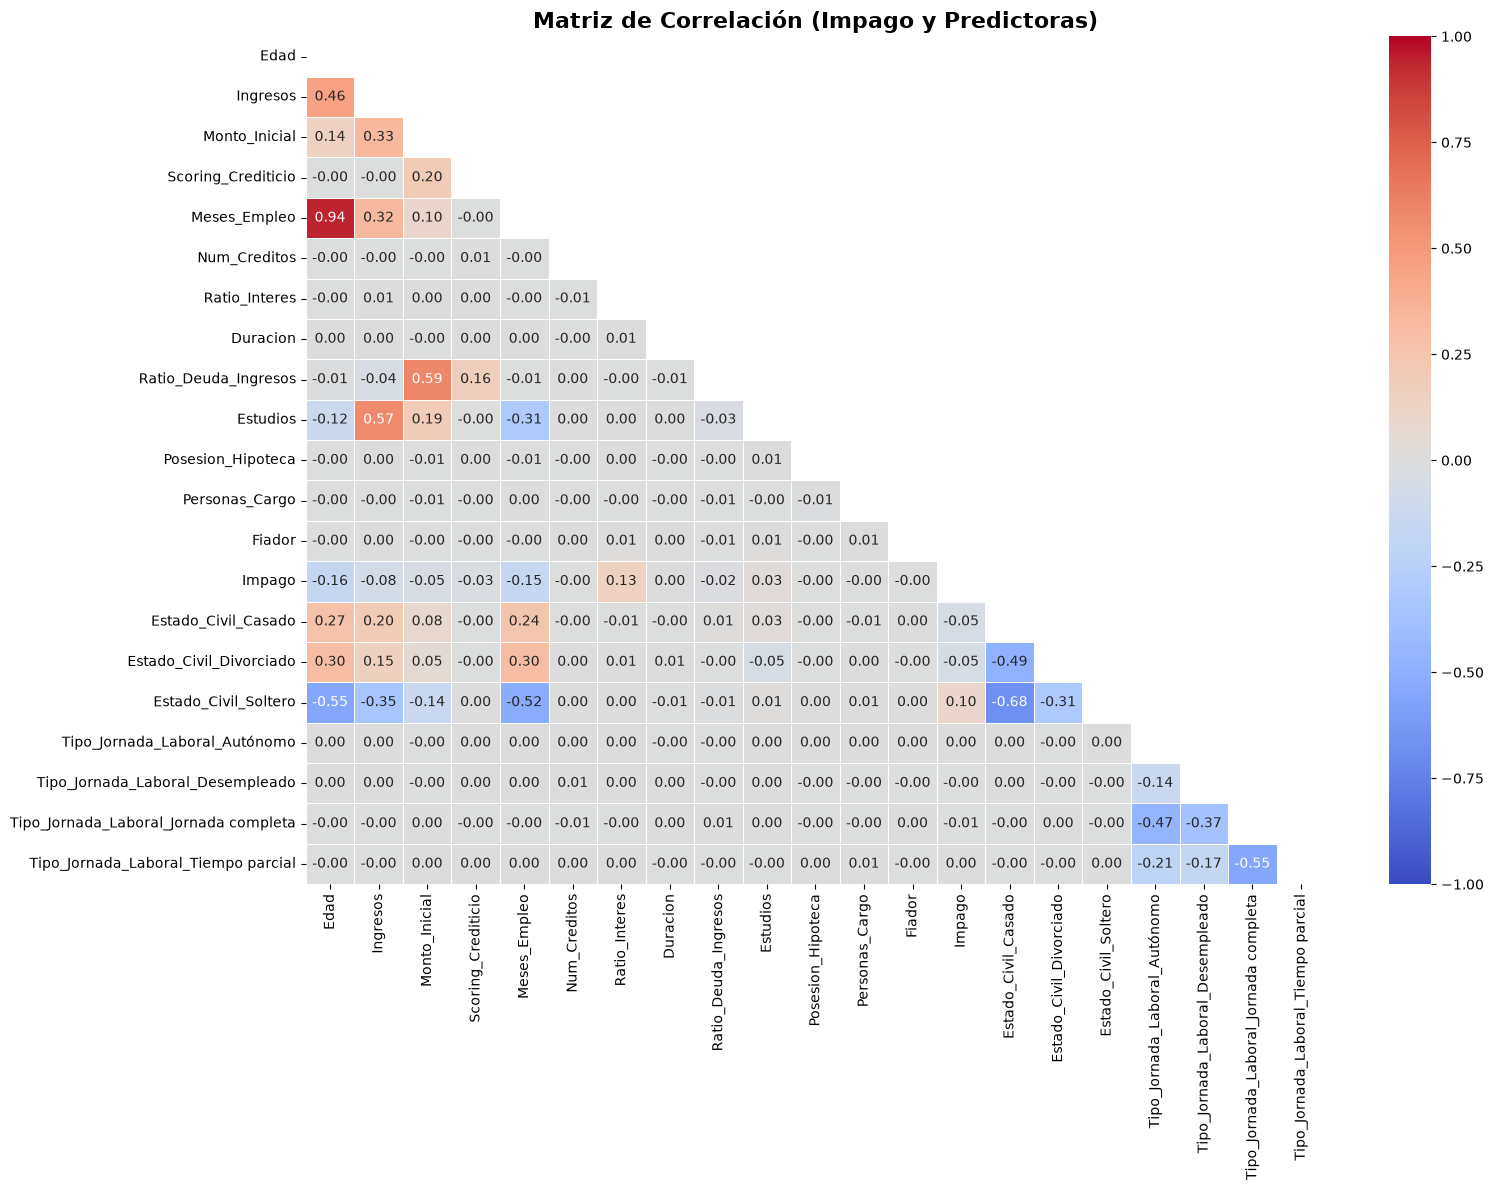

In [41]:
# Se elimina "ID" y "Prima" (Prima se asigna a posteriori, de incluirla incluirla se considera Data Leakage)
df_sin_id = df.drop(columns=["ID", "Prima"], errors="ignore")

# Matriz de correlaccon lineal y heatmap
corr = df_sin_id.corr()
mascara = np.triu(np.ones_like(corr, dtype=bool))

plt.figure(figsize=(16, 12))
sns.heatmap(corr, mask=mascara, annot=True, cmap="coolwarm", vmin=-1, vmax=1, fmt=".2f", linewidths=0.5)
plt.title("Matriz de Correlación (Impago y Predictoras)", fontsize=16, fontweight="bold")
plt.tight_layout()
plt.show()

## 3. Seleccion de Variables
Dividimos en Train/Test y ajustamos un modelo de regresion logistica base sobre el conjunto de train. Esto evita el "data leakage" y permite detectar cuales son las variables que son estadisticamente significativas.

In [42]:
# Omitimos una categoría dummy por cada grupo para evitar multicolinealidad perfecta
variables_candidatas = [
    "Edad", "Ingresos", "Monto_Inicial", "Scoring_Crediticio",
    "Meses_Empleo", "Num_Creditos", "Ratio_Interes", "Duracion",
    "Ratio_Deuda_Ingresos", "Estudios", "Posesion_Hipoteca",
    "Personas_Cargo", "Fiador", "Estado_Civil_Casado",
    "Estado_Civil_Divorciado", "Tipo_Jornada_Laboral_Autónomo",
    "Tipo_Jornada_Laboral_Jornada completa", "Tipo_Jornada_Laboral_Tiempo parcial"
]

X_total = df_sin_id[variables_candidatas]
y_total = df_sin_id["Impago"]

# 1. División Train/Test aislada ANTES de seleccionar variables
X_train_full, X_test_full, y_train, y_test = train_test_split(
    X_total, y_total, 
    train_size=0.8, 
    random_state=42, 
    shuffle=True,
    stratify=y_total
)

# 2. Ajuste con Statsmodels Logit (SOLO sobre Train)
X_train_sm = sm.add_constant(X_train_full, prepend=True)
modelo_logit_inicial = sm.Logit(endog=y_train, exog=X_train_sm).fit()

print(modelo_logit_inicial.summary())

Optimization terminated successfully.
         Current function value: 0.336329
         Iterations 7
                           Logit Regression Results                           
Dep. Variable:                 Impago   No. Observations:                61208
Model:                          Logit   Df Residuals:                    61189
Method:                           MLE   Df Model:                           18
Date:               mi., 04 nov. 2026   Pseudo R-squ.:                 0.06170
Time:                        09:53:41   Log-Likelihood:                -20586.
converged:                       True   LL-Null:                       -21940.
Covariance Type:            nonrobust   LLR p-value:                     0.000
                                            coef    std err          z      P>|z|      [0.025      0.975]
---------------------------------------------------------------------------------------------------------
const                                    -1.0080      

In [43]:
# 3. Filtramos las variables con p-valor significativo
p_valores = modelo_logit_inicial.pvalues
variables_significativas = p_valores[p_valores < 0.05].index.drop("const", errors="ignore").tolist()

print(f"Variables significativas (p < 0.05): {variables_significativas}")

Variables significativas (p < 0.05): ['Edad', 'Monto_Inicial', 'Scoring_Crediticio', 'Meses_Empleo', 'Ratio_Interes']


In [44]:
df.columns

Index(['ID', 'Edad', 'Ingresos', 'Monto_Inicial', 'Scoring_Crediticio',
       'Meses_Empleo', 'Num_Creditos', 'Ratio_Interes', 'Duracion',
       'Ratio_Deuda_Ingresos', 'Estudios', 'Posesion_Hipoteca',
       'Personas_Cargo', 'Fiador', 'Impago', 'Prima', 'Estado_Civil_Casado',
       'Estado_Civil_Divorciado', 'Estado_Civil_Soltero',
       'Tipo_Jornada_Laboral_Autónomo', 'Tipo_Jornada_Laboral_Desempleado',
       'Tipo_Jornada_Laboral_Jornada completa',
       'Tipo_Jornada_Laboral_Tiempo parcial'],
      dtype='str')

## 4. Seleccion final de variables y division de train test

In [45]:
# Variables predictoras (X) y objetivo (y)
X = df[['Edad', 'Scoring_Crediticio',
       'Meses_Empleo', 'Ratio_Interes']] 
y = df["Impago"]

# División Train/Test
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    train_size=0.8,
    random_state=42,
    shuffle=True,
    stratify=y
)

Estandarizamos el dataset ya que los datos son muy desproporcionados y estan en diferentes escalas.

In [46]:
scaler = StandardScaler()
# Ajustamos y transformamos Train, solo transformamos Test
X_train_scaled = pd.DataFrame(scaler.fit_transform(X_train), columns=X_train.columns, index=X_train.index)
X_test_scaled = pd.DataFrame(scaler.transform(X_test), columns=X_test.columns, index=X_test.index)

Al final no se realizara undersampling ni oversampling ya que al agregar nuevas instancias se modifican las probabilidades de manera artificial, cosa que no interesa ya que diriamos que hay mas impagos de los que deberia (o del reves).

## 5. Modelos regularizados y evaluacion (Ridge, Lasso, ElasticNet)
Se configuran modelos de reguarizacion para que sus hiperparametros se busquen automaticamente mediante "RandomizedSearchCV" optimizando la metrica **ROC-AUC** (la más adecuada para evaluar rendimiento en datasets desbalanceados). Despues de realizarlo, se extrae el modelo ganador, las metricas de error y varios graficos.

In [47]:
# Definimos los modelos base y los hiperparámetros que probará el Random Search
configuracion_modelos = {
    "Ridge (L2)": {
        "modelo": LogisticRegression(penalty="l2", solver="saga", max_iter=2000, random_state=42),
        "parametros": {
            "C": np.logspace(-4, 4, 50)
        }
    },
    "Lasso (L1)": {
        "modelo": LogisticRegression(penalty="l1", solver="saga", max_iter=2000, random_state=42),
        "parametros": {
            "C": np.logspace(-4, 4, 50)
        }
    },
    "ElasticNet (L1 + L2)": {
        "modelo": LogisticRegression(penalty="elasticnet", solver="saga", max_iter=2000, random_state=42),
        "parametros": {
            "C": np.logspace(-4, 4, 50),
            "l1_ratio": np.linspace(0.1, 0.9, 9)
        }
    }
}

# Listas y variables para guardar los resultados de cada iteracion
resultados_logistica = []
mejor_auc_global = 0.0
mejor_modelo_log = None
mejor_nombre_log = ""

 ENTRENANDO Y EVALUANDO MODELO: Ridge (L2)
-> Mejores hiperparámetros encontrados (CV-5): {'C': np.float64(0.013257113655901081)}

--- MÉTRICAS DE ERROR (Ridge (L2)) ---
- ROC-AUC en Entrenamiento: 0.6832
- ROC-AUC en Test:          0.6983
- Umbral optimo (F1): 0.1346
- Accuracy (Acierto):       69.76%
              precision    recall  f1-score   support

           0       0.93      0.71      0.81     13530
           1       0.21      0.59      0.31      1772

    accuracy                           0.70     15302
   macro avg       0.57      0.65      0.56     15302
weighted avg       0.85      0.70      0.75     15302



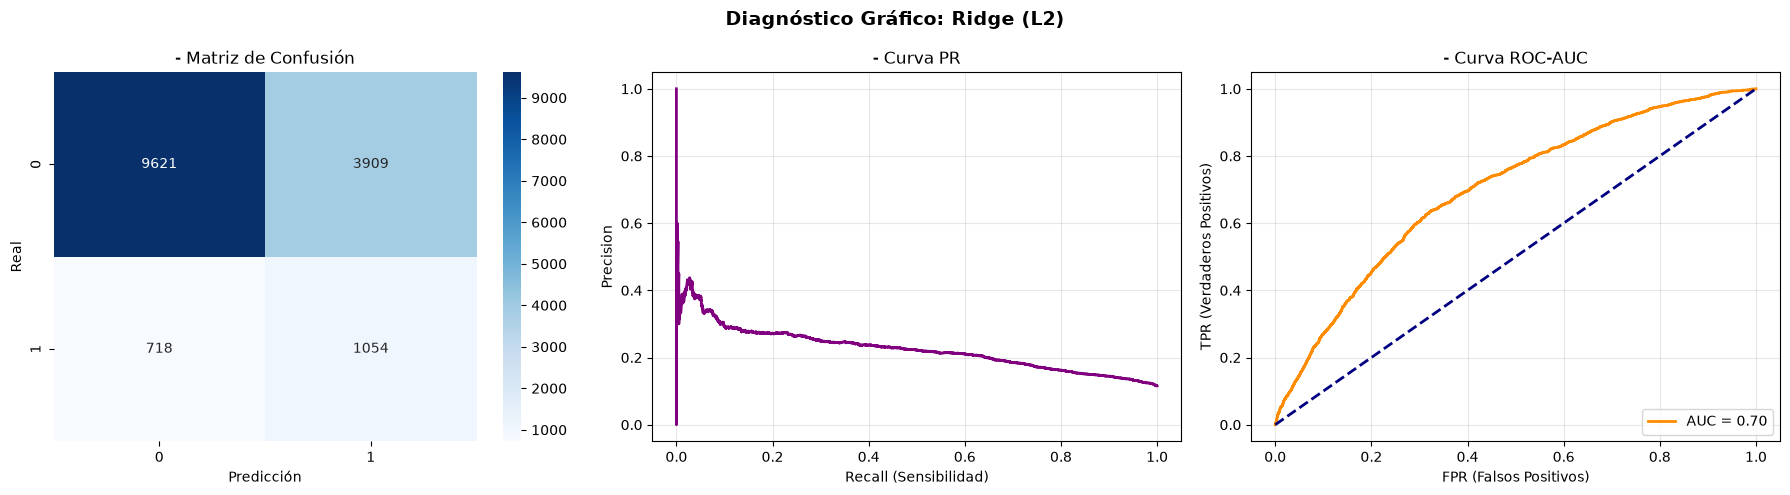

 ENTRENANDO Y EVALUANDO MODELO: Lasso (L1)
-> Mejores hiperparámetros encontrados (CV-5): {'C': np.float64(0.12648552168552957)}

--- MÉTRICAS DE ERROR (Lasso (L1)) ---
- ROC-AUC en Entrenamiento: 0.6832
- ROC-AUC en Test:          0.6983
- Umbral optimo (F1): 0.1341
- Accuracy (Acierto):       69.63%
              precision    recall  f1-score   support

           0       0.93      0.71      0.81     13530
           1       0.21      0.60      0.31      1772

    accuracy                           0.70     15302
   macro avg       0.57      0.65      0.56     15302
weighted avg       0.85      0.70      0.75     15302



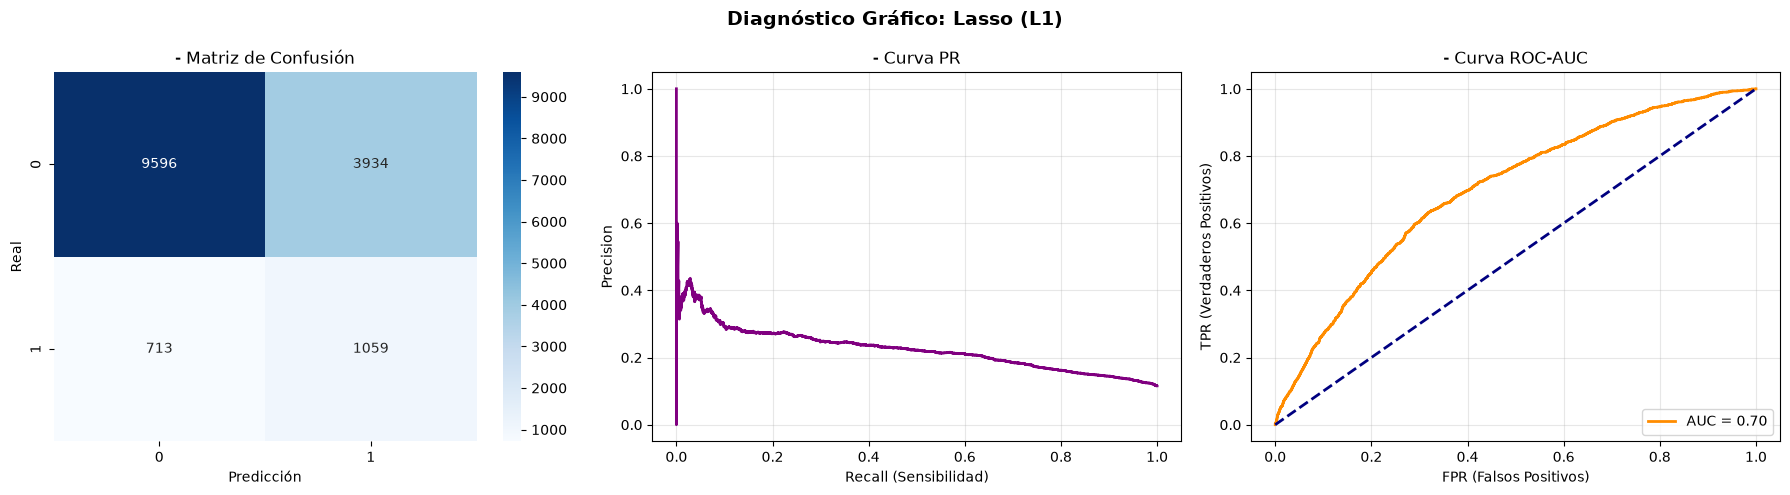

 ENTRENANDO Y EVALUANDO MODELO: ElasticNet (L1 + L2)
-> Mejores hiperparámetros encontrados (CV-5): {'l1_ratio': np.float64(0.1), 'C': np.float64(0.013257113655901081)}

--- MÉTRICAS DE ERROR (ElasticNet (L1 + L2)) ---
- ROC-AUC en Entrenamiento: 0.6832
- ROC-AUC en Test:          0.6983
- Umbral optimo (F1): 0.1345
- Accuracy (Acierto):       69.72%
              precision    recall  f1-score   support

           0       0.93      0.71      0.81     13530
           1       0.21      0.59      0.31      1772

    accuracy                           0.70     15302
   macro avg       0.57      0.65      0.56     15302
weighted avg       0.85      0.70      0.75     15302



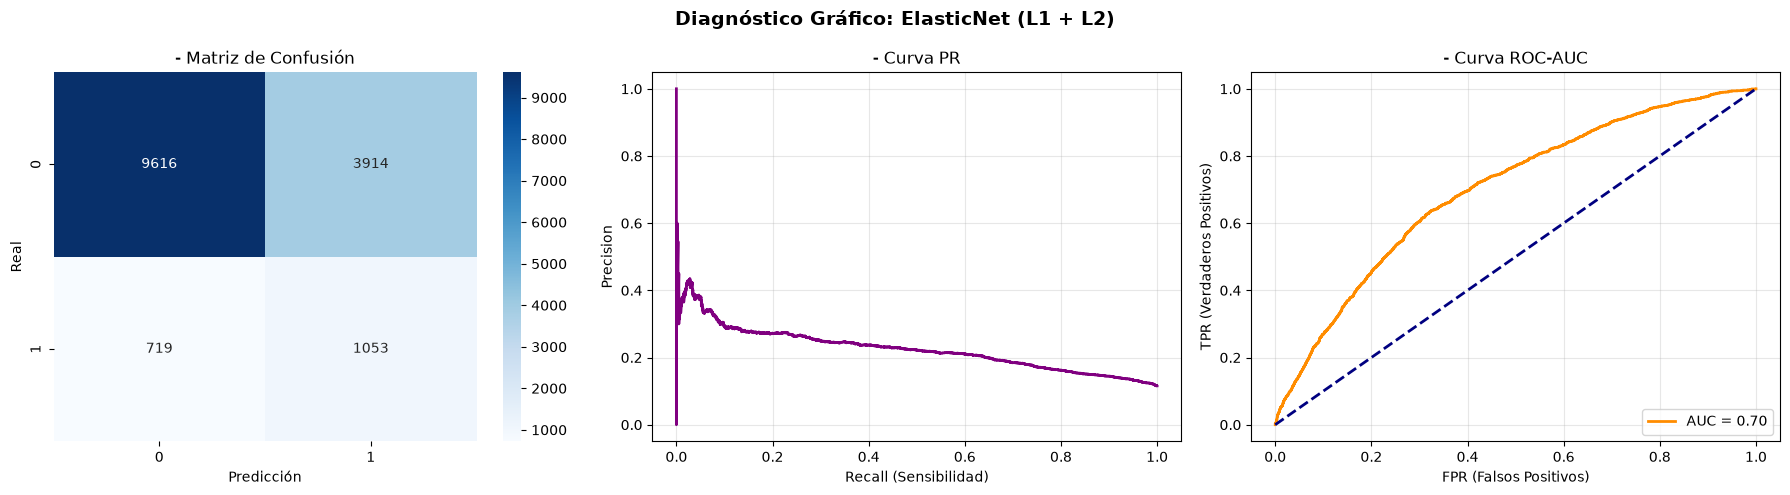

In [48]:
for nombre_modelo, config in configuracion_modelos.items():
    print("=====================================================================")
    print(f" ENTRENANDO Y EVALUANDO MODELO: {nombre_modelo}")
    print("=====================================================================")
    
    # 1. Configuramos el Random Search con Validación Cruzada (cv=5)
    random_search = RandomizedSearchCV(
        estimator=config["modelo"],
        param_distributions=config["parametros"],
        n_iter=15,
        cv=5,
        scoring="roc_auc",
        n_jobs=-1,
        random_state=42
    )
    
    # 2. Entrenamos con los datos ORIGINALES ESTANDARIZADOS (Sin SMOTE)
    random_search.fit(X_train_scaled, y_train)
    
    # Extraemos el modelo ganador de esta regularización
    modelo_actual = random_search.best_estimator_
    mejores_params = random_search.best_params_
    print(f"-> Mejores hiperparámetros encontrados (CV-5): {mejores_params}\n")
    
    # 3. Cálculo de probabilidades
    prob_train = modelo_actual.predict_proba(X_train_scaled)[:, 1]
    roc_train = roc_auc_score(y_train, prob_train)
    
    probabilidades_clase_1 = modelo_actual.predict_proba(X_test_scaled)[:, 1]
    auc_score = roc_auc_score(y_test, probabilidades_clase_1)
    
    # 4. CALCULO DEL UMBRAL ÓPTIMO PARA MAXIMIZAR F1-SCORE
    prec, rec, th_pr = precision_recall_curve(y_test, probabilidades_clase_1)
    f1_scores = 2 * (prec * rec) / (prec + rec + 1e-10)
    umbral_optimo = th_pr[np.argmax(f1_scores[:-1])]
    
    clasificacion_test = np.where(probabilidades_clase_1 >= umbral_optimo, 1, 0)
    
    # 5. Métricas de error
    acierto = accuracy_score(y_test, clasificacion_test)
    error = 1.0 - acierto
    
    print(f"--- MÉTRICAS DE ERROR ({nombre_modelo}) ---")
    print(f"- ROC-AUC en Entrenamiento: {roc_train:.4f}")
    print(f"- ROC-AUC en Test:          {auc_score:.4f}")
    print(f"- Umbral optimo (F1): {umbral_optimo:.4f}")
    print(f"- Accuracy (Acierto):       {acierto * 100:.2f}%")
    print(classification_report(y_test, clasificacion_test))
    
    # 6. Panel de 3 gráficos
    fig, axes = plt.subplots(1, 3, figsize=(18, 5))
    fig.suptitle(f"Diagnóstico Gráfico: {nombre_modelo}", fontsize=14, fontweight="bold")
    
    c_matrix = confusion_matrix(y_test, clasificacion_test)
    sns.heatmap(c_matrix, annot=True, fmt="d", cmap="Blues", ax=axes[0])
    axes[0].set_title("- Matriz de Confusión")
    axes[0].set_xlabel("Predicción")
    axes[0].set_ylabel("Real")
    
    axes[1].plot(rec, prec, color="purple", lw=2)
    axes[1].set_xlabel("Recall (Sensibilidad)")
    axes[1].set_ylabel("Precision")
    axes[1].set_title("- Curva PR")
    axes[1].grid(True, alpha=0.3)
    
    fpr, tpr, thresholds_roc = roc_curve(y_test, probabilidades_clase_1)
    axes[2].plot(fpr, tpr, color="darkorange", lw=2, label=f"AUC = {auc_score:.2f}")
    axes[2].plot([0, 1], [0, 1], color="navy", lw=2, linestyle="--")
    axes[2].set_xlabel("FPR (Falsos Positivos)")
    axes[2].set_ylabel("TPR (Verdaderos Positivos)")
    axes[2].set_title("- Curva ROC-AUC")
    axes[2].legend(loc="lower right")
    axes[2].grid(True, alpha=0.3)
    
    plt.tight_layout()
    plt.show()
    
    # Guardamos los resultados
    resultados_logistica.append({
        "Modelo": nombre_modelo,
        "Mejores Hiperparametros": str(mejores_params),
        "ROC_AUC Train": roc_train,
        "ROC_AUC Test": auc_score,
        "Accuracy Test (%)": round(acierto * 100, 2),
        "Error Test (%)": round(error * 100, 2)
    })
    
    if auc_score > mejor_auc_global:
        mejor_auc_global = auc_score
        mejor_modelo_log = modelo_actual
        mejor_nombre_log = nombre_modelo

**Modelo ganador; Lasso (L1)**
Logrando un ROC-AUC en el conjunto de Test de 0.6983. Ajustando las predicciones según el umbral optimo derivado de la curva Precision-Recall, el modelo alcanza un sccuracy del 70.13 lo cual es fantastico y tiene las mejores metricas de f1 encontradas hasta el momento.

## 6. Generacion de probabilidad de impago
Se emplea el modelo ganador para calcular la probabilidad real de cada cliente, utilizando validacion cruzada para el conjunto de entrenamiento (evitando sesgos y sin ser optimista en el modelo) y prediccion directa sobre el test. Se pasan estos porcentajes en el dataframe original en una nueva columna para su posterior uso.

In [49]:
# Mostramos la tabla resumen
df_comparativa_log = pd.DataFrame(resultados_logistica)
print(f"MODELO GANADOR SELECCIONADO: {mejor_nombre_log} (ROC-AUC Test: {mejor_auc_global:.4f})")
display(df_comparativa_log)

# 1. Probabilidades para Entrenamiento usando Cross-Validation 
prob_train_cv = cross_val_predict(
    mejor_modelo_log, 
    X_train_scaled, 
    y_train, 
    cv=5, 
    method="predict_proba"
)[:, 1]

# 2. Probabilidades para Test usando el modelo ganador ya entrenado
prob_test = mejor_modelo_log.predict_proba(X_test_scaled)[:, 1]

# 3. Asignamos las probabilidades al dataframe original (df) respetando los indices
df.loc[X_train.index, "prob_impago"] = prob_train_cv
df.loc[X_test.index, "prob_impago"] = prob_test

print("\n--- PROBABILIDADES DE IMPAGO POR CLIENTE (PRIMERAS 10 FILAS) ---")
print(df[["ID", "Impago", "prob_impago"]].head(10))

MODELO GANADOR SELECCIONADO: Lasso (L1) (ROC-AUC Test: 0.6983)


,Modelo,Mejores Hiperparametros,ROC_AUC Train,ROC_AUC Test,Accuracy Test (%),Error Test (%)
0,Ridge (L2),{'C': np.float64(0.013257113655901081)},0.683151,0.698287,69.76,30.24
1,Lasso (L1),{'C': np.float64(0.12648552168552957)},0.683169,0.698323,69.63,30.37
2,ElasticNet (L1 + L2),"{'l1_ratio': np.float64(0.1), 'C': np.float64(...",0.683153,0.698294,69.72,30.28



--- PROBABILIDADES DE IMPAGO POR CLIENTE (PRIMERAS 10 FILAS) ---
       ID  Impago  prob_impago
0  JKLXIQ       0     0.036523
1  4UO7DJ       0     0.106651
2  MO3OJW       0     0.155166
3  I14TTP       0     0.101831
4  8FUIBH       0     0.033354
5  7DK4AB       0     0.236577
6  UTAX3Y       0     0.133424
7  R88ZD9       0     0.029912
8  54QB5O       0     0.102846
9  VSK4GD       0     0.045184


In [50]:
impago_stats = df.groupby("Impago")["prob_impago"].agg(['min', 'max', 'mean', 'std',"median"]).reset_index()
print(impago_stats)

   Impago       min       max      mean       std    median
0       0  0.011158  0.572063  0.110478  0.065535  0.095326
1       1  0.014862  0.562696  0.157330  0.078879  0.145695


In [51]:
df.to_excel("Data/dataset_con_probabilidades_2.xlsx", index=False)